**AlexNet** is a landmark Convolutional Neural Network (CNN) created by Alex Krizhevsky, Ilya Sutskever, and Geoffrey Hinton in 2012. By winning the ImageNet Large Scale Visual Recognition Challenge (ILSVRC) by a wide margin, it proved that deep CNNs trained on GPUs could solve large-scale visual recognition and sparked the modern deep learning boom.

---

### Core Architecture

AlexNet scales up the convolutional blueprint introduced by LeNet-5 to handle higher-resolution RGB images (typically 224×224×3) and 1,000 object classes. It contains **8 learned layers**—**5 convolutional layers** followed by **3 fully connected layers** (with ~60 million parameters):

* **Conv1:** Large 11×11 kernels with stride 4 to rapidly downsample spatial dimensions while capturing broad features.
* **Conv2–Conv5:** Progressive 5×5 and 3×3 convolutional layers with max pooling to build hierarchical visual representations, from edges and textures to object parts.
* **FC6–FC8:** Dense layers with 4,096 neurons each in FC6 and FC7, ending in a 1,000-way output layer for ImageNet classification.

---

### Key Innovations Over LeNet

AlexNet succeeded where earlier networks hit training and scaling walls by combining several practical breakthroughs:

* **ReLU Activations:** Replaced saturating activations like `tanh` and sigmoid with ReLU, speeding up convergence several-fold.
* **GPU Parallelization:** Split the model across two GPUs because single-GPU memory in 2012 could not hold the full network and large batches.
* **Dropout Regularization:** Randomly dropped units during training in the fully connected layers to curb overfitting across tens of millions of parameters.
* **Data Augmentation & Overlapping Pooling:** Used image crops, horizontal flips, and overlapping pooling windows to improve generalization and reduce error rates.

---

### Why It Matters in the LeNet-to-ResNet Progression

LeNet-5 showed that weight-sharing CNNs work on small grayscale digits, while AlexNet showed how to scale depth, data, and GPU compute to natural photos. However, pushing depth much further past AlexNet ran into vanishing gradients and optimization bottlenecks—a challenge directly addressed later by architectures like VGGNet and ResNet.

### 1. AlexNet Architecture in PyTorch

Below is a clean `nn.Module` implementation of AlexNet with **5 convolutional layers** and **3 fully connected layers**, using ReLU activations and Dropout in the classifier head.

In [1]:
import torch
import torch.nn as nn


class AlexNet(nn.Module):

  def __init__(self, num_classes=10, dropout=0.5):
    super().__init__()
    # Expects input shape: [Batch, 3, 224, 224]
    self.features = nn.Sequential(
        nn.Conv2d(3, 64, kernel_size=11, stride=4, padding=2),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
        nn.Conv2d(64, 192, kernel_size=5, padding=2),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
        nn.Conv2d(192, 384, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(384, 256, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.Conv2d(256, 256, kernel_size=3, padding=1),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=3, stride=2),
    )

    self.avgpool = nn.AdaptiveAvgPool2d((6, 6))

    self.classifier = nn.Sequential(
        nn.Dropout(p=dropout),
        nn.Linear(256 * 6 * 6, 4096),
        nn.ReLU(inplace=True),
        nn.Dropout(p=dropout),
        nn.Linear(4096, 4096),
        nn.ReLU(inplace=True),
        nn.Linear(4096, num_classes),
    )

  def forward(self, x):
    x = self.features(x)
    x = self.avgpool(x)
    x = torch.flatten(x, 1)
    x = self.classifier(x)
    return x

*(Note: Classic 2012 AlexNet used Local Response Normalization after the first two pooling stages; modern PyTorch implementations commonly omit it in favor of batch normalization or simpler ReLU + Dropout stacks.)*

---

### 2. Training on an Image Dataset (CIFAR-10 Example)

This training script resizes CIFAR-10 images to 224×224 so they match the spatial progression of the standard AlexNet layers, logs training and test metrics per epoch, and saves loss/accuracy plots.

[INFO] Training AlexNet on device: cuda


100%|██████████| 170M/170M [13:44<00:00, 207kB/s]


Epoch [1/10] | Batch [100/391] | Loss: 2.2228
Epoch [1/10] | Batch [200/391] | Loss: 2.0106
Epoch [1/10] | Batch [300/391] | Loss: 1.8558
--> Epoch [1/10] | Train Loss: 1.9904 | Test Acc: 42.98%
Epoch [2/10] | Batch [100/391] | Loss: 1.6172
Epoch [2/10] | Batch [200/391] | Loss: 1.4377
Epoch [2/10] | Batch [300/391] | Loss: 1.4956
--> Epoch [2/10] | Train Loss: 1.4051 | Test Acc: 54.76%
Epoch [3/10] | Batch [100/391] | Loss: 1.1756
Epoch [3/10] | Batch [200/391] | Loss: 1.1233
Epoch [3/10] | Batch [300/391] | Loss: 1.0952
--> Epoch [3/10] | Train Loss: 1.0906 | Test Acc: 67.94%
Epoch [4/10] | Batch [100/391] | Loss: 0.9264
Epoch [4/10] | Batch [200/391] | Loss: 0.9378
Epoch [4/10] | Batch [300/391] | Loss: 1.1514
--> Epoch [4/10] | Train Loss: 0.8950 | Test Acc: 71.82%
Epoch [5/10] | Batch [100/391] | Loss: 0.6363
Epoch [5/10] | Batch [200/391] | Loss: 0.5797
Epoch [5/10] | Batch [300/391] | Loss: 0.9117
--> Epoch [5/10] | Train Loss: 0.7595 | Test Acc: 76.60%
Epoch [6/10] | Batch [100

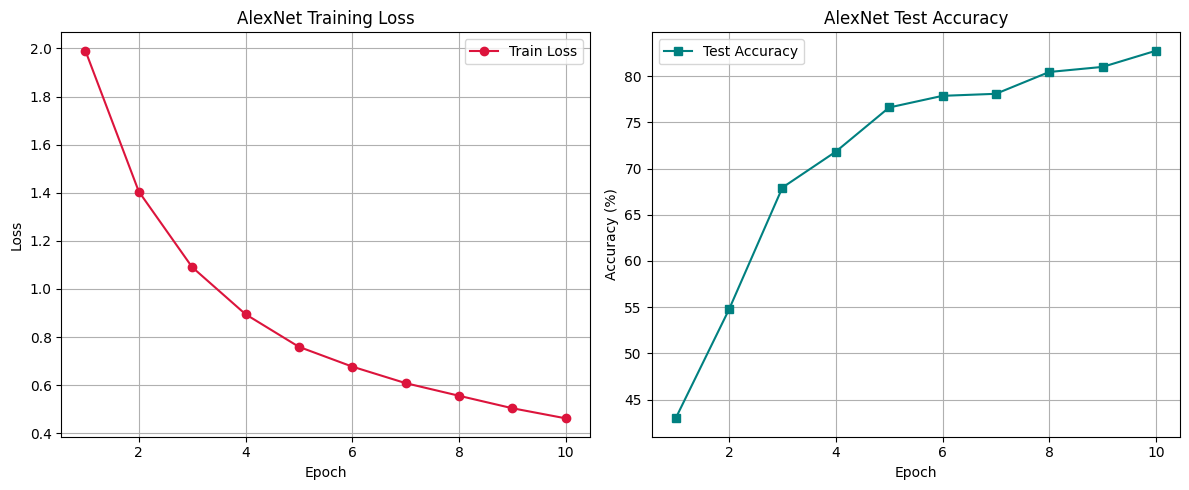

In [2]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

# 1. Device & Data Preparation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Training AlexNet on device: {device}")

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=test_transform
)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

# 2. Model, Loss, and Optimizer
model = AlexNet(num_classes=10, dropout=0.5).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(
    model.parameters(), lr=0.01, momentum=0.9, weight_decay=5e-4
)

# 3. Training & Evaluation Loop
num_epochs = 10
train_losses, test_accuracies = [], []

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0

  for batch_idx, (images, targets) in enumerate(train_loader):
    images, targets = images.to(device), targets.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, targets)
    loss.backward()
    optimizer.step()

    running_loss += loss.item() * images.size(0)

    if (batch_idx + 1) % 100 == 0:
      print(
          f"Epoch [{epoch+1}/{num_epochs}] | Batch [{batch_idx+1}/{len(train_loader)}] | Loss: {loss.item():.4f}"
      )

  epoch_loss = running_loss / len(train_dataset)
  train_losses.append(epoch_loss)

  # Evaluate on test set
  model.eval()
  correct, total = 0, 0
  with torch.no_grad():
    for images, targets in test_loader:
      images, targets = images.to(device), targets.to(device)
      outputs = model(images)
      _, predicted = torch.max(outputs, 1)
      total += targets.size(0)
      correct += (predicted == targets).sum().item()

  test_acc = (correct / total) * 100
  test_accuracies.append(test_acc)
  print(
      f"--> Epoch [{epoch+1}/{num_epochs}] | Train Loss: {epoch_loss:.4f} | Test Acc: {test_acc:.2f}%"
  )

# 4. Plot Training Loss & Test Accuracy
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    marker="o",
    color="crimson",
    label="Train Loss",
)
plt.title("AlexNet Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    range(1, num_epochs + 1),
    test_accuracies,
    marker="s",
    color="teal",
    label="Test Accuracy",
)
plt.title("AlexNet Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.savefig("alexnet_cifar10_metrics.png")
print("[INFO] Saved plot to 'alexnet_cifar10_metrics.png'")
plt.show()

### 3. Practical Tips for Training AlexNet

* **Upscaling vs. Customizing Stride:** Resizing 32×32 CIFAR-10 images to 224×224 lets you keep the classic AlexNet layer shapes, but increases memory and compute cost. For native 32×32 images, reduce the first convolution stride from `4` to `1` and kernel size from `11` to `3` or `5`.
* **Transfer Learning Shortcut:** In real-world projects with smaller datasets, load pretrained weights (`models.alexnet(weights=models.AlexNet_Weights.DEFAULT)`) and replace only `model.classifier[6]` with `nn.Linear(4096, num_classes)` instead of training all ~60 million parameters from scratch.
* **Regularization & Learning Rate:** AlexNet has large fully connected layers that overfit easily on small datasets; use `Dropout`, `weight_decay`, data augmentation, and a learning rate scheduler (`StepLR` or `CosineAnnealingLR`) if training for many epochs.